In [37]:
import importlib
import os
import sys

REPO = "/home/hey4/rich_tde"
sys.path.insert(0, os.path.join(REPO, "dev"))
os.environ["MPLCONFIGDIR"] = os.path.join(REPO, ".cache", "matplotlib")

In [38]:
import dev

# isort: split
import matplotlib.pyplot as plt
import numpy as np

import richio

%matplotlib inline

importlib.reload(dev)  # Reapply the repository style when rerunning setup.
print(f"Plotting style: {dev.__file__}")

FIGSIZE = (5, 4.5)
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
G_CODE = richio.units.lscale**3 / (richio.units.mscale * richio.units.tscale**2)

Plotting style: /home/hey4/rich_tde/dev/dev/__init__.py


For stellar cells (`mask_star_ratio`, as in `1.0-compression.ipynb`), use
$m_i=\rho_i V_i$ and $\epsilon_i=v_i^2/2+\Phi(r_i)$ in the BH frame.
$\Phi=-GM_{\rm BH}/(r-r_s)$ outside $h=0.6r_p$, with a continuous harmonic
continuation inside $h$. We use the run's $G=1$ and
$r_s=4.21(M_{\rm BH}/10^6)\,R_{\rm code}$ conventions; thermal energy and
self-gravity are excluded from orbital energy.

$$
\Delta\epsilon=\frac{GM_{\rm BH}R_\star}{r_t^2},\qquad
r_t=R_\star\left(\frac{M_{\rm BH}}{M_\star}\right)^{1/3},\qquad
\frac{dM}{d\epsilon}\simeq\frac{\sum_{i\ {\rm in\ bin}}m_i}{\delta\epsilon}.
$$

For bound bins, use the [Keplerian mapping](https://academic.oup.com/mnras/article/526/2/2323/7279472):
$$
T(\epsilon)=\frac{2\pi GM_{\rm BH}}{(-2\epsilon)^{3/2}},\qquad
\dot M_{\rm fb}(T)=\frac{dM}{d\epsilon}\left|\frac{d\epsilon}{dT}\right|
=\frac{dM}{d\epsilon}\frac{2|\epsilon|}{3T},\qquad
 t_{\rm fb}=T(-\Delta\epsilon).
$$

$T$ is the inferred orbital return time measured from disruption, not the snapshot
time or a delay added to it. These are ballistic estimates from the instantaneous
energy distributions; the Keplerian mapping approximates the softened potential
and does not measure the actual fallback flux. The energy ordinate is in
$M_\star/\Delta\epsilon$; all mass histograms retain their absolute normalization.

The fixed bin width is $0.025\,\Delta\epsilon$; return-time sampling becomes sparse toward the late-time end of the fallback plots.

## 1e4

In [39]:
RUN = "1e4"
TFBS = [0.2, 0.5]
M_BH = 1e4 * richio.units.mscale
M_STAR = 0.5 * richio.units.mscale
R_STAR = 0.47 * richio.units.lscale
BETA = 1
EPSILON_EDGES = np.linspace(-10, 5, 601)  # In units of frozen-in Delta epsilon.

gm = G_CODE * M_BH
r_t = R_STAR * (M_BH / M_STAR) ** (1 / 3)
r_p = r_t / BETA
r_s = 4.21 * (M_BH / (1e6 * richio.units.mscale)) * richio.units.lscale
h = 0.6 * r_p  # S60 in these run names.
delta_epsilon = gm * R_STAR / r_t**2
t_fb = 2 * np.pi * gm / (2 * delta_epsilon) ** 1.5
energy_edges = EPSILON_EDGES * delta_epsilon
energy = 0.5 * (energy_edges[:-1] + energy_edges[1:])
print(
    f"{RUN}: Delta epsilon = {delta_epsilon.to('erg/g'):.6e}, "
    f"t_fb = {t_fb.to('day'):.6f}"
)

1e4: Delta epsilon = 5.506528e+16 erg/g, t_fb = 2.656021 day


In [40]:
times = []
distributions = []
for path in dev.SNAPSHOT_TFB(RUN, TFBS):
    # The selected full snapshots already contain BH-frame positions/velocities.
    assert os.path.basename(path).startswith("snap_full_"), "Need a BH-frame snapshot"
    snap = richio.load(path)
    time = (snap.time.squeeze() / t_fb).to("dimensionless")
    star = snap.mask_star_ratio()
    radius = np.sqrt(snap.X[star] ** 2 + snap.Y[star] ** 2 + snap.Z[star] ** 2)
    speed_squared = snap.vx[star] ** 2 + snap.vy[star] ** 2 + snap.vz[star] ** 2
    mass = (snap.density * snap.volume)[star]

    # Match the potential and its derivative at the softening radius.
    potential = -gm / (np.maximum(radius, h) - r_s)
    inner = radius < h
    potential[inner] += gm / (2 * h * (h - r_s) ** 2) * (radius[inner] ** 2 - h**2)
    epsilon = 0.5 * speed_squared + potential
    bin_mass, _ = np.histogram(epsilon, bins=energy_edges, weights=mass)
    dM_depsilon = bin_mass / np.diff(energy_edges)
    times.append(time)
    distributions.append(dM_depsilon)

    below = mass[epsilon < energy_edges[0]].sum()
    above = mass[epsilon > energy_edges[-1]].sum()
    print(
        f"{path}\n  t/t_fb = {float(time):.4f}; selected = {mass.sum().to('Msun'):.6f}; "
        f"bound = {mass[epsilon < 0].sum().to('Msun'):.6f}\n"
        f"  outside bins: below = {below.to('Msun'):.3e}, "
        f"above = {above.to('Msun'):.3e}"
    )
    assert np.isclose((bin_mass.sum() + below + above) / mass.sum(), 1)
    del snap, star, radius, speed_squared, mass, potential, inner, epsilon

/data1/projects/pi-rossiem/TDE_data/NewSnellius/R0.47M0.5BH10000beta1S60ComptonHiRes/snap_full_38.h5
  t/t_fb = 0.2049; selected = 0.502928 Msun; bound = 0.252180 Msun
  outside bins: below = 0.000e+00 Msun, above = 0.000e+00 Msun
/data1/projects/pi-rossiem/TDE_data/NewSnellius/R0.47M0.5BH10000beta1S60ComptonHiRes/snap_full_54.h5
  t/t_fb = 0.5053; selected = 0.502928 Msun; bound = 0.252072 Msun
  outside bins: below = 2.575e-08 Msun, above = 1.511e-10 Msun


1e4: specific orbital energy distribution


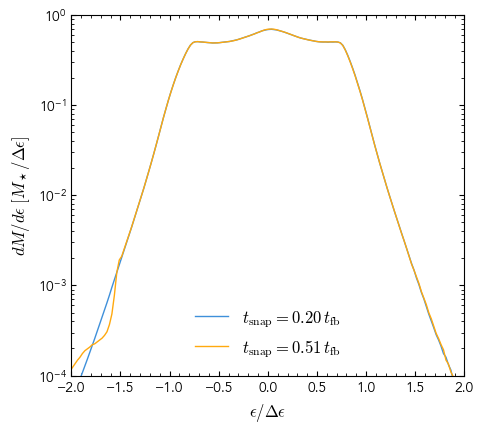

In [41]:
print(f"{RUN}: specific orbital energy distribution")
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, (time, dM_depsilon) in enumerate(zip(times, distributions)):
    ax.plot(
        energy / delta_epsilon,
        delta_epsilon * dM_depsilon / M_STAR,
        color=COLORS[i],
        label=rf"$t_{{\rm snap}}={float(time):.2f}\,t_{{\rm fb}}$",
    )
ax.set(
    xlabel=r"$\epsilon/\Delta\epsilon$",
    ylabel=r"$dM/d\epsilon\;[M_\star/\Delta\epsilon]$",
    yscale="log",
    xlim=(EPSILON_EDGES[0], EPSILON_EDGES[-1]),
)
ax.legend()
ax.set(xlim=(-2, 2), ylim=(1e-4, 1))
fig.tight_layout()
plt.show()

1e4: inferred fallback rate; legends identify snapshot times


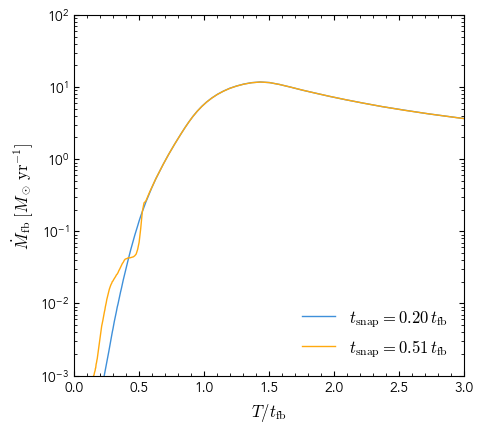

In [ ]:
# Increasing negative-energy bin centres map to increasing return times.
bound = energy < 0
return_time = 2 * np.pi * gm / (-2 * energy[bound]) ** 1.5
depsilon_dt = 2 * np.abs(energy[bound]) / (3 * return_time)
fallback_rates = [
    (dM_depsilon[bound] * depsilon_dt).to("Msun/yr") for dM_depsilon in distributions
]

print(f"{RUN}: inferred fallback rate; legends identify snapshot times")
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, (time, mdot) in enumerate(zip(times, fallback_rates)):
    ax.plot(
        return_time / t_fb,
        mdot,
        color=COLORS[i],
        label=rf"$t_{{\rm snap}}={float(time):.2f}\,t_{{\rm fb}}$",
    )
ax.set(
    xlabel=r"$t\,[t_{\rm fb}]$",
    ylabel=r"$\dot M_{\rm fb}\;[M_\odot\,\mathrm{yr}^{-1}]$",
    yscale="log",
    xlim=(0, 3),
    ylim=(1e-3, 1e2)
)
ax.legend()
fig.tight_layout()
plt.show()

## 1e5

In [43]:
RUN = "1e5"
TFBS = [0.2, 0.5]
M_BH = 1e5 * richio.units.mscale
M_STAR = 0.5 * richio.units.mscale
R_STAR = 0.47 * richio.units.lscale
BETA = 1
EPSILON_EDGES = np.linspace(-10, 5, 601)  # In units of frozen-in Delta epsilon.

gm = G_CODE * M_BH
r_t = R_STAR * (M_BH / M_STAR) ** (1 / 3)
r_p = r_t / BETA
r_s = 4.21 * (M_BH / (1e6 * richio.units.mscale)) * richio.units.lscale
h = 0.6 * r_p  # S60 in these run names.
delta_epsilon = gm * R_STAR / r_t**2
t_fb = 2 * np.pi * gm / (2 * delta_epsilon) ** 1.5
energy_edges = EPSILON_EDGES * delta_epsilon
energy = 0.5 * (energy_edges[:-1] + energy_edges[1:])
print(
    f"{RUN}: Delta epsilon = {delta_epsilon.to('erg/g'):.6e}, "
    f"t_fb = {t_fb.to('day'):.6f}"
)

1e5: Delta epsilon = 1.186345e+17 erg/g, t_fb = 8.399075 day


In [44]:
times = []
distributions = []
for path in dev.SNAPSHOT_TFB(RUN, TFBS):
    # The selected full snapshots already contain BH-frame positions/velocities.
    assert os.path.basename(path).startswith("snap_full_"), "Need a BH-frame snapshot"
    snap = richio.load(path)
    time = (snap.time.squeeze() / t_fb).to("dimensionless")
    star = snap.mask_star_ratio()
    radius = np.sqrt(snap.X[star] ** 2 + snap.Y[star] ** 2 + snap.Z[star] ** 2)
    speed_squared = snap.vx[star] ** 2 + snap.vy[star] ** 2 + snap.vz[star] ** 2
    mass = (snap.density * snap.volume)[star]

    # Match the potential and its derivative at the softening radius.
    potential = -gm / (np.maximum(radius, h) - r_s)
    inner = radius < h
    potential[inner] += gm / (2 * h * (h - r_s) ** 2) * (radius[inner] ** 2 - h**2)
    epsilon = 0.5 * speed_squared + potential
    bin_mass, _ = np.histogram(epsilon, bins=energy_edges, weights=mass)
    dM_depsilon = bin_mass / np.diff(energy_edges)
    times.append(time)
    distributions.append(dM_depsilon)

    below = mass[epsilon < energy_edges[0]].sum()
    above = mass[epsilon > energy_edges[-1]].sum()
    print(
        f"{path}\n  t/t_fb = {float(time):.4f}; selected = {mass.sum().to('Msun'):.6f}; "
        f"bound = {mass[epsilon < 0].sum().to('Msun'):.6f}\n"
        f"  outside bins: below = {below.to('Msun'):.3e}, "
        f"above = {above.to('Msun'):.3e}"
    )
    assert np.isclose((bin_mass.sum() + below + above) / mass.sum(), 1)
    del snap, star, radius, speed_squared, mass, potential, inner, epsilon

/data1/projects/pi-rossiem/TDE_data/YujieSnellius/R0.47M0.5BH100000beta1S60n1.5ComptonHiResNewAMR/snap_full_86.h5
  t/t_fb = 0.1987; selected = 0.502879 Msun; bound = 0.251710 Msun
  outside bins: below = 0.000e+00 Msun, above = 0.000e+00 Msun
/data1/projects/pi-rossiem/TDE_data/YujieSnellius/R0.47M0.5BH100000beta1S60n1.5ComptonHiResNewAMR/snap_full_142.h5
  t/t_fb = 0.4975; selected = 0.502843 Msun; bound = 0.251683 Msun
  outside bins: below = 5.340e-08 Msun, above = 0.000e+00 Msun


1e5: specific orbital energy distribution


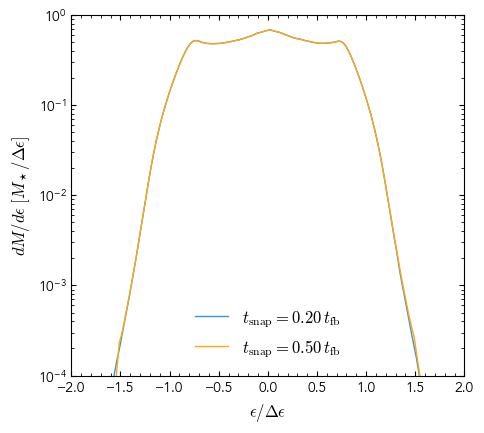

In [45]:
print(f"{RUN}: specific orbital energy distribution")
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, (time, dM_depsilon) in enumerate(zip(times, distributions)):
    ax.plot(
        energy / delta_epsilon,
        delta_epsilon * dM_depsilon / M_STAR,
        color=COLORS[i],
        label=rf"$t_{{\rm snap}}={float(time):.2f}\,t_{{\rm fb}}$",
    )
ax.set(
    xlabel=r"$\epsilon/\Delta\epsilon$",
    ylabel=r"$dM/d\epsilon\;[M_\star/\Delta\epsilon]$",
    yscale="log",
    xlim=(EPSILON_EDGES[0], EPSILON_EDGES[-1]),
)
ax.legend()
ax.set(xlim=(-2, 2), ylim=(1e-4, 1))
fig.tight_layout()
plt.show()

1e5: inferred fallback rate; legends identify snapshot times


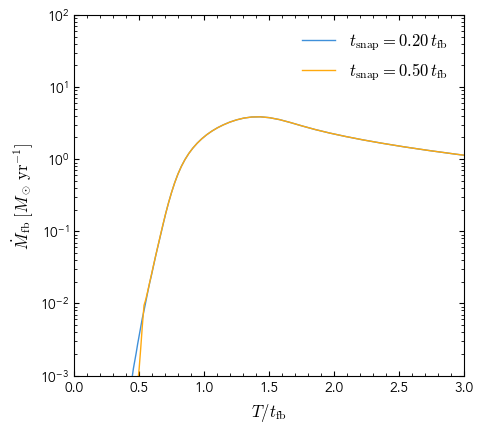

In [ ]:
# Increasing negative-energy bin centres map to increasing return times.
bound = energy < 0
return_time = 2 * np.pi * gm / (-2 * energy[bound]) ** 1.5
depsilon_dt = 2 * np.abs(energy[bound]) / (3 * return_time)
fallback_rates = [
    (dM_depsilon[bound] * depsilon_dt).to("Msun/yr") for dM_depsilon in distributions
]

print(f"{RUN}: inferred fallback rate; legends identify snapshot times")
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, (time, mdot) in enumerate(zip(times, fallback_rates)):
    ax.plot(
        return_time / t_fb,
        mdot,
        color=COLORS[i],
        label=rf"$t_{{\rm snap}}={float(time):.2f}\,t_{{\rm fb}}$",
    )
ax.set(
    xlabel=r"$t\,[t_{\rm fb}]$",
    ylabel=r"$\dot M_{\rm fb}\;[M_\odot\,\mathrm{yr}^{-1}]$",
    yscale="log",
    xlim=(0, 3),
    ylim=(1e-3, 1e2)
)
ax.legend()
fig.tight_layout()
plt.show()